<a href="https://colab.research.google.com/github/JuanitaRozo/Redes_Neuronales_III/blob/main/Practica3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Carga de datos, librerías de evaluación y preprocesamiento

En esta celda inicial realizamos la configuración del entorno para garantizar la reproducibilidad y preparar el conjunto de datos de **Fashion MNIST**:

* **Importación de librerías**: Cargamos numpy para el manejo de vectores, matplotlib para las visualizaciones, tensorflow para construir y entrenar las redes neuronales, y diversas herramientas de scikit-learn para calcular métricas de evaluación (Accuracy, Precision, Recall, F1-Score) y visualizar la matriz de confusión.
* **Fijación de semilla aleatoria**: Usamos `tf.keras.utils.set_random_seed(42) para que los experimentos y la inicialización de los pesos de la red sean reproducibles.
* **División del Dataset**:
  * Cargamos originalmente los conjuntos de entrenamiento (x_total, y_total) y prueba (x_test, y_test).
  * Dividimos el conjunto de entrenamiento original para extraer un **10%** destinado a validación (x_dev, y_dev), asegurando una división estratificada (stratify=y_total) para mantener la proporción de clases constante.
* **Normalización**: Escalamos las intensidades de los píxeles de las imágenes de un rango [0, 255] a [0.0, 1.0] dividiendo por 255.0. Esto facilita y acelera la convergencia durante el entrenamiento de la red.

In [ ]:
#Cargamos los datos y las librerías de evaluación


import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

tf.keras.utils.set_random_seed(42)

(x_total, y_total), (x_test, y_test) = (
    tf.keras.datasets.fashion_mnist.load_data()
)

x_train, x_dev, y_train, y_dev = train_test_split(
    x_total,
    y_total,
    test_size=0.10,
    random_state=42,
    stratify=y_total
)

x_train = x_train.astype("float32") / 255.0
x_dev = x_dev.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

class_names = [
    "Camiseta", "Pantalón", "Suéter", "Vestido", "Abrigo",
    "Sandalia", "Camisa", "Zapatilla", "Bolso", "Bota"
]

print("Datos preparados correctamente.")


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Datos preparados correctamente.


### 2. Definición de la arquitectura de los modelos

Definimos dos funciones para construir y comparar dos arquitecturas de redes neuronales artificiales secuenciales utilizando Keras:

* **Modelo Base (Sin Regularización)**:
  * Flatten: Redimensiona las imágenes de entrada de 2D (28, 28) a un vector unidimensional de 784 elementos.
  * Dos capas ocultas densamente conectadas (Dense) con 256 y 128 neuronas respectivamente, utilizando la función de activación **ReLU**.
  * Una capa de salida con 10 neuronas (una por clase) con activación **Softmax** para obtener una distribución de probabilidad sobre las clases.

* **Modelo Regularizado (Con L2 y Dropout)**:
  * Mantiene la misma estructura de capas del modelo base, pero introduce técnicas para combatir el sobreajuste (overfitting):
  * **Regularización L2 (kernel_regularizer)**: Penaliza los pesos grandes en las capas densas sumando un término proporcional al cuadrado de los pesos a la función de pérdida (con un factor de 0.001).
  * **Dropout**: Apaga aleatoriamente un porcentaje de neuronas durante cada paso de entrenamiento (30% en la primera capa oculta y 20% en la segunda) para obligar a la red a aprender representaciones redundantes y robustas.

In [ ]:
#vamos a construir dos modelos comparables


def crear_modelo_base():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(256, activation="relu"),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax")
    ])

def crear_modelo_regularizado():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(
            256,
            activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(0.001)
        ),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(
            128,
            activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(0.001)
        ),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(10, activation="softmax")
    ])


### 3. Función de entrenamiento y ejecución del flujo con Early Stopping

En esta etapa definimos la lógica de compilación y entrenamiento, y ejecutamos el proceso para ambos modelos:

* **Compilación**: Configura el optimizador **Adam** con una tasa de aprendizaje de 0.001, la función de pérdida sparse_categorical_crossentropy (adecuada para etiquetas enteras) y la métrica de exactitud (accuracy).
* **Early Stopping (Parada Temprana)**: Creamos un callback que monitorea la pérdida en el conjunto de validación (val_loss). Si esta no mejora durante 3 épocas consecutivas (patience=3), el entrenamiento se detiene para evitar el sobreajuste y se restauran los mejores pesos obtenidos (restore_best_weights=True).
* **Entrenamiento**: Se entrenan de forma independiente el modelo base y el modelo regularizado bajo las mismas condiciones (hasta 20 épocas y con un tamaño de lote de 128), guardando el historial de métricas de cada uno.

In [ ]:
#entrenamos aplicando Early Stopping


def entrenar_modelo(modelo):
    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    parada_temprana = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    historia = modelo.fit(
        x_train, y_train,
        validation_data=(x_dev, y_dev),
        epochs=20,
        batch_size=128,
        callbacks=[parada_temprana],
        verbose=1
    )

    return historia

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

modelo_base = crear_modelo_base()
historia_base = entrenar_modelo(modelo_base)

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

modelo_regularizado = crear_modelo_regularizado()
historia_regularizado = entrenar_modelo(modelo_regularizado)

print("Entrenamiento de ambos modelos finalizado.")


Epoch 1/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8161 - loss: 0.5203 - val_accuracy: 0.8580 - val_loss: 0.4046
Epoch 2/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8642 - loss: 0.3746 - val_accuracy: 0.8753 - val_loss: 0.3459
Epoch 3/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8767 - loss: 0.3341 - val_accuracy: 0.8808 - val_loss: 0.3266
Epoch 4/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8865 - loss: 0.3074 - val_accuracy: 0.8782 - val_loss: 0.3168
Epoch 5/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8933 - loss: 0.2865 - val_accuracy: 0.8835 - val_loss: 0.3129
Epoch 6/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8987 - loss: 0.2689 - val_accuracy: 0.8857 - val_loss: 0.3124
Epoch 7/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9026 - loss: 0.2574 - val_accuracy: 0.8800 - val_loss: 0.3214
Epoch 8/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9092 - loss: 0.2440 - val_accuracy: 0.

### 4. Visualización de las curvas de pérdida (Loss)

Graficamos el comportamiento de la función de pérdida tanto en el conjunto de entrenamiento como en el de validación a lo largo de las épocas para ambos modelos.

Esta gráfica es fundamental para diagnosticar el comportamiento de la red:
* Nos permite observar visualmente si el **Modelo Base** comienza a sufrir de sobreajuste (cuando la pérdida de entrenamiento sigue bajando pero la de validación comienza a subir).
* Nos ayuda a contrastar si el **Modelo Regularizado** logra mantener un comportamiento de pérdida de validación más estable y cercano a la pérdida de entrenamiento.

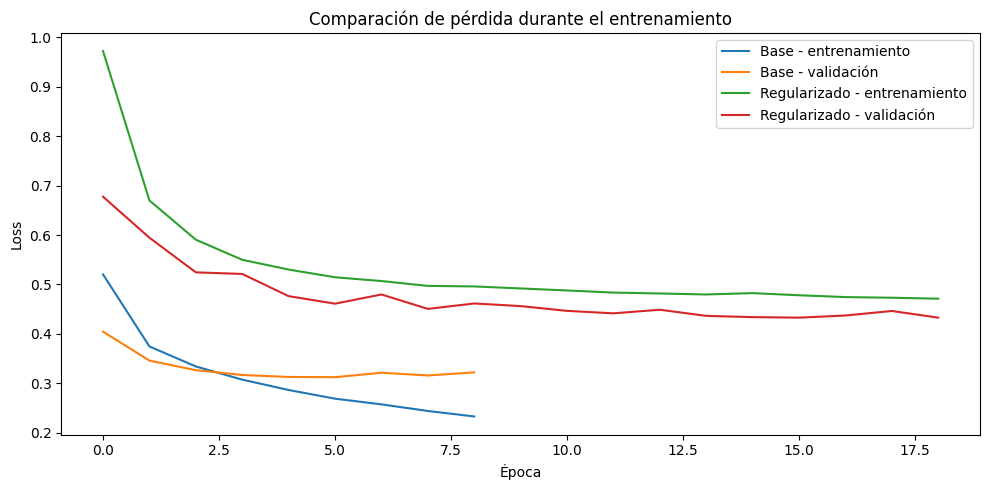

In [ ]:
#comparamos las curvas de perdidas

plt.figure(figsize=(10, 5))

plt.plot(
    historia_base.history["loss"],
    label="Base - entrenamiento"
)
plt.plot(
    historia_base.history["val_loss"],
    label="Base - validación"
)
plt.plot(
    historia_regularizado.history["loss"],
    label="Regularizado - entrenamiento"
)
plt.plot(
    historia_regularizado.history["val_loss"],
    label="Regularizado - validación"
)

plt.title("Comparación de pérdida durante el entrenamiento")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()


### 5. Selección del mejor modelo y evaluación final en el conjunto de prueba

En esta fase se toma la decisión de qué modelo utilizar y se realiza la evaluación con los datos de prueba (test):

* **Selección del Modelo**: Comparamos de forma automática la pérdida mínima de validación obtenida por ambos modelos. El modelo que haya alcanzado la menor pérdida es seleccionado como el modelo_final para la evaluación final.
* **Predicción**: Usamos el modelo seleccionado para realizar predicciones sobre el conjunto de datos de prueba (x_test), que se ha mantenido aislado durante todo el diseño.
* **Cálculo de Métricas Globales**: Evaluamos la calidad de las predicciones utilizando:
  * **Accuracy**: Proporción total de predicciones correctas.
  * **Precision**: Capacidad del modelo para no clasificar como positiva una muestra que es negativa (promedio macro).
  * **Recall**: Capacidad del modelo para encontrar todos los casos positivos (promedio macro).
  * **F1-Score**: La media armónica entre precisión y sensibilidad (promedio macro).
* **Reporte de Clasificación**: Desglosa las métricas de precisión, recall y F1-score de manera individual para cada una de las 10 categorías de prendas de vestir.

In [ ]:
#aqui evaluamos con las métricas requeridas


perdida_base = min(historia_base.history["val_loss"])
perdida_regularizada = min(
    historia_regularizado.history["val_loss"]
)

if perdida_regularizada < perdida_base:
    modelo_final = modelo_regularizado
    nombre_final = "Regularizado"
else:
    modelo_final = modelo_base
    nombre_final = "Base"

print("Modelo seleccionado:", nombre_final)
print("Pérdida de validación base:", round(perdida_base, 4))
print(
    "Pérdida de validación regularizada:",
    round(perdida_regularizada, 4)
)

# Evaluación final: utilizar test una sola vez
probabilidades = modelo_final.predict(x_test, verbose=0)
y_pred = np.argmax(probabilidades, axis=1)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)
recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)
f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print("\nMÉTRICAS DEL MODELO FINAL")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

print("\nReporte por clase:")
print(classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    zero_division=0
))


Modelo seleccionado: Base
Pérdida de validación base: 0.3124
Pérdida de validación regularizada: 0.4328

MÉTRICAS DEL MODELO FINAL
Accuracy:  0.8720
Precision: 0.8756
Recall:    0.8720
F1 Score:  0.8711

Reporte por clase:
              precision    recall  f1-score   support

    Camiseta       0.85      0.79      0.82      1000
    Pantalón       0.99      0.96      0.98      1000
      Suéter       0.71      0.84      0.77      1000
     Vestido       0.78      0.95      0.85      1000
      Abrigo       0.84      0.68      0.75      1000
    Sandalia       0.97      0.97      0.97      1000
      Camisa       0.73      0.66      0.69      1000
   Zapatilla       0.94      0.96      0.95      1000
       Bolso       0.98      0.97      0.97      1000
        Bota       0.97      0.95      0.96      1000

    accuracy                           0.87     10000
   macro avg       0.88      0.87      0.87     10000
weighted avg       0.88      0.87      0.87     10000



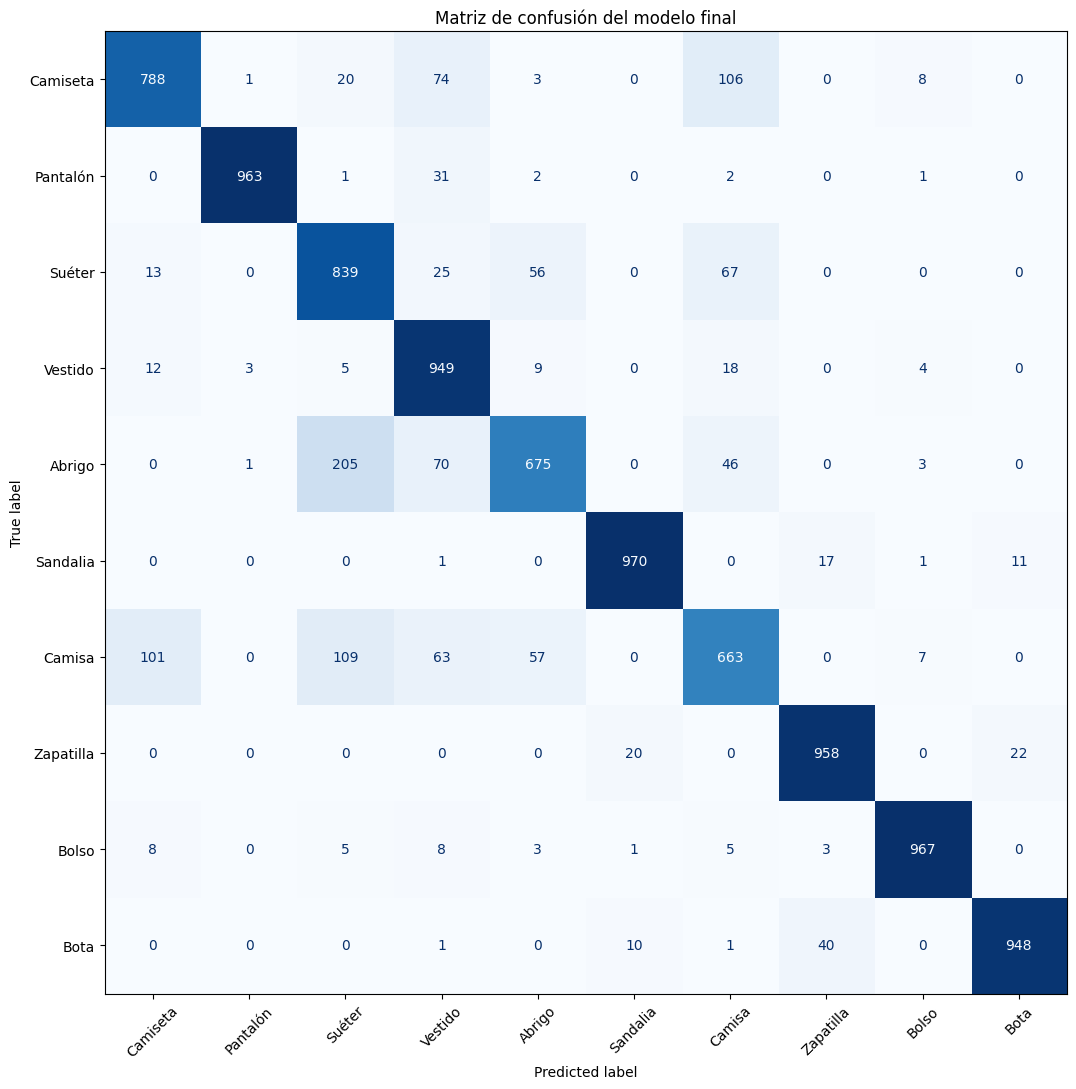

In [ ]:
#creamos la matriz de confusion


matriz = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(11, 11))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title("Matriz de confusión del modelo final")
plt.tight_layout()
plt.show()
